# CSE-CIC-IDS2018 - Bi-LSTM Multi-class Intrusion Detection (Training)

Trains a **per-flow** Bi-LSTM classifier on the tensors produced by `01_preprocessing.ipynb`.

## Why per-flow and not sliding windows?

CICFlowMeter already aggregates packet sequences into per-flow statistical features. Building LSTM windows over **row-shuffled** flows (as the previous notebook did) gave the LSTM unrelated rows as 'sequence' — the model had nothing to learn and hallucinated. Published implementations (Ramyaelineni 2020, Wang 2023) classify one flow at a time, reshaping the feature vector into a `(timesteps, features_per_step)` pseudo-sequence so the LSTM can still learn local feature interactions.

## Architecture

1. Input: one flow = `F` features, reshaped to `(T=F/chunk, C=chunk)`.
2. Bi-LSTM (2 layers, hidden=128, dropout=0.3).
3. Attention pooling over time steps.
4. Dense(64) -> Dropout -> Dense(num_classes).
5. **Class-weighted focal loss** (handles extreme imbalance).
6. AdamW + OneCycleLR, early stopping on macro-F1.
7. Evaluation: per-attack precision/recall/F1, confusion matrix, per-class ROC.

## 0 - Imports

In [2]:
import os, json, pickle, random, time, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                              roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__}  |  device={device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

PyTorch 2.5.1+cu121  |  device=cuda
GPU: NVIDIA GeForce RTX 2070 with Max-Q Design


## 1 - Load preprocessed tensors

In [3]:
NOTEBOOK_DIR = Path.cwd()
DATA_DIR     = NOTEBOOK_DIR / 'processed'
OUT_DIR      = NOTEBOOK_DIR / 'outputs'
OUT_DIR.mkdir(exist_ok=True)

assert DATA_DIR.exists(), f'Run 01_preprocessing.ipynb first (missing {DATA_DIR})'

X_train = np.load(DATA_DIR / 'X_train.npy')
y_train = np.load(DATA_DIR / 'y_train.npy')
X_val   = np.load(DATA_DIR / 'X_val.npy')
y_val   = np.load(DATA_DIR / 'y_val.npy')
X_test  = np.load(DATA_DIR / 'X_test.npy')
y_test  = np.load(DATA_DIR / 'y_test.npy')
class_weights_np = np.load(DATA_DIR / 'class_weights.npy')

with open(DATA_DIR / 'class_names.json') as f:
    class_names = json.load(f)
with open(DATA_DIR / 'label_encoder.pkl', 'rb') as f:
    label_encoder = pickle.load(f)
with open(DATA_DIR / 'scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

num_features = X_train.shape[1]
num_classes  = len(class_names)
print(f'Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}')
print(f'Features: {num_features} | Classes: {num_classes}')
print(f'Train dist: {dict(Counter(y_train.tolist()))}')

Train: (990870, 47) | Val: (212329, 47) | Test: (212330, 47)
Features: 47 | Classes: 15
Train dist: {5: 140000, 14: 65852, 0: 280000, 1: 101822, 7: 28984, 4: 140000, 12: 85305, 8: 140000, 10: 6936, 6: 1211, 2: 399, 3: 160, 11: 66, 9: 75, 13: 60}


## 1b - SMOTE oversampling for tiny classes

The preprocessing pipeline caps classes but doesn't synthesize anything, so classes like `BruteForce-XSS` and `SQL-Injection` have 60–400 training flows. A WeightedRandomSampler alone would just replay the same 60 flows thousands of times (pure memorization). SMOTE interpolates between real minority flows to give the model *diverse* synthetic samples. We only touch the training set — val/test stay untouched so the evaluation is honest.

In [ ]:
try:
    from imblearn.over_sampling import SMOTE
except ImportError as e:
    raise ImportError(
        "imbalanced-learn is not installed. Run:\n"
        "    pip install imbalanced-learn\n"
        "then restart the kernel and re-run this notebook."
    ) from e

from sklearn.utils.class_weight import compute_class_weight

TARGET_MIN = 3_000   # floor for every class after SMOTE (lowered from 10k so we don't inflate 60 real flows into 10k synthetic)

pre_counts = Counter(y_train.tolist())
print('Before SMOTE:')
for c in sorted(pre_counts):
    print(f'  {class_names[c]:22s} {pre_counts[c]:>8,}')

sampling_strategy = {
    c: TARGET_MIN
    for c in range(num_classes)
    if pre_counts.get(c, 0) < TARGET_MIN
}

if sampling_strategy:
    min_minor = min(pre_counts[c] for c in sampling_strategy)
    k = max(1, min(5, min_minor - 1))
    print(f'\nApplying SMOTE to {len(sampling_strategy)} classes -> {TARGET_MIN:,} each (k_neighbors={k})')
    smote = SMOTE(sampling_strategy=sampling_strategy, k_neighbors=k, random_state=SEED)
    X_train, y_train = smote.fit_resample(X_train, y_train)
    X_train = X_train.astype(np.float32)
    y_train = y_train.astype(np.int64)

    post_counts = Counter(y_train.tolist())
    print('\nAfter SMOTE:')
    for c in sorted(post_counts):
        delta = post_counts[c] - pre_counts.get(c, 0)
        mark = f'  (+{delta:,})' if delta else ''
        print(f'  {class_names[c]:22s} {post_counts[c]:>8,}{mark}')

    # Recompute class weights against the new (much more balanced) distribution.
    class_weights_np = compute_class_weight(
        'balanced', classes=np.arange(num_classes), y=y_train
    ).astype(np.float32)
    print(f'\nRecomputed class weights (mean={class_weights_np.mean():.3f}, '
          f'min={class_weights_np.min():.3f}, max={class_weights_np.max():.3f})')
    print(f'New X_train shape: {X_train.shape}')
else:
    print('All classes already above target — no SMOTE applied.')

## 2 - Hyper-parameters

In [ ]:
# ---- Input reshape ----
# Feature vector -> pseudo-sequence (timesteps, features_per_step).
# We pad the feature vector to a multiple of CHUNK, then reshape.
CHUNK = 4            # features per timestep
PAD_TO = ((num_features + CHUNK - 1) // CHUNK) * CHUNK
T_STEPS = PAD_TO // CHUNK
print(f'Reshape: {num_features} features -> pad to {PAD_TO} -> ({T_STEPS} steps, {CHUNK} feats/step)')

# ---- Training ----
BATCH_SIZE    = 1024
EPOCHS        = 30
LR            = 1e-3
WEIGHT_DECAY  = 1e-5
HIDDEN        = 128
LSTM_LAYERS   = 2
DROPOUT       = 0.30
PATIENCE      = 8
GRAD_CLIP     = 1.0
FOCAL_GAMMA   = 2.0        # standard focal loss; sampler is off so no double-counting
USE_SAMPLER   = False       # OFF: triple-stacked rebalancing collapsed Benign recall (Option B fix)
NUM_WORKERS   = 0          # Windows: keep 0 to avoid pickling issues

print(f'Batch={BATCH_SIZE}, LR={LR}, hidden={HIDDEN}, layers={LSTM_LAYERS}, epochs={EPOCHS}')
print(f'WeightedRandomSampler={USE_SAMPLER}, focal_gamma={FOCAL_GAMMA}, patience={PATIENCE}')

## 3 - Dataset (per-flow, no sliding window)

In [6]:
from torch.utils.data import WeightedRandomSampler


class FlowDataset(Dataset):
    """One flow -> one sample. Pads features to PAD_TO and reshapes to (T, CHUNK)."""
    def __init__(self, X, y, pad_to, chunk):
        n, f = X.shape
        if f < pad_to:
            X = np.pad(X, ((0, 0), (0, pad_to - f)), mode='constant')
        # -> (N, T, C)
        self.X = torch.from_numpy(X.reshape(n, pad_to // chunk, chunk).astype(np.float32))
        self.y = torch.from_numpy(y.astype(np.int64))

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_ds = FlowDataset(X_train, y_train, PAD_TO, CHUNK)
val_ds   = FlowDataset(X_val,   y_val,   PAD_TO, CHUNK)
test_ds  = FlowDataset(X_test,  y_test,  PAD_TO, CHUNK)

pin = device.type == 'cuda'

if USE_SAMPLER:
    # Per-sample weight = 1 / class_frequency so each class is drawn equally often.
    # This is the single biggest lever for minority-class macro-F1 on CIC-IDS2018.
    class_counts = np.bincount(y_train, minlength=num_classes).astype(np.float64)
    per_class_w  = 1.0 / np.clip(class_counts, 1, None)
    sample_w     = per_class_w[y_train]
    sampler = WeightedRandomSampler(
        weights=torch.from_numpy(sample_w).double(),
        num_samples=len(sample_w),
        replacement=True,
    )
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                              pin_memory=pin, num_workers=NUM_WORKERS, drop_last=True)
    print('Using WeightedRandomSampler: each minibatch is class-balanced in expectation.')
    print('  per-class counts:', dict(zip(range(num_classes), class_counts.astype(int).tolist())))
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              pin_memory=pin, num_workers=NUM_WORKERS, drop_last=True)

val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE*2, shuffle=False,
                          pin_memory=pin, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False,
                          pin_memory=pin, num_workers=NUM_WORKERS)

print(f'train batches={len(train_loader)} | val batches={len(val_loader)} | test batches={len(test_loader)}')
sample_x, sample_y = next(iter(train_loader))
print(f'sample batch: X={tuple(sample_x.shape)}  y={tuple(sample_y.shape)}')
print(f'sample batch class counts: {dict(Counter(sample_y.tolist()))}')

Using WeightedRandomSampler: each minibatch is class-balanced in expectation.
  per-class counts: {0: 280000, 1: 101822, 2: 10000, 3: 10000, 4: 140000, 5: 140000, 6: 10000, 7: 28984, 8: 140000, 9: 10000, 10: 10000, 11: 10000, 12: 85305, 13: 10000, 14: 65852}
train batches=1027 | val batches=104 | test batches=104
sample batch: X=(1024, 12, 4)  y=(1024,)
sample batch class counts: {0: 64, 1: 65, 14: 74, 13: 61, 11: 72, 10: 62, 4: 79, 7: 67, 9: 67, 8: 74, 2: 71, 3: 72, 12: 72, 5: 71, 6: 53}


## 4 - Model

In [7]:
class Attention(nn.Module):
    """Additive attention over time steps."""
    def __init__(self, dim):
        super().__init__()
        self.w = nn.Linear(dim, dim)
        self.v = nn.Linear(dim, 1, bias=False)

    def forward(self, x):            # x: (B, T, D)
        e = torch.tanh(self.w(x))    # (B, T, D)
        a = F.softmax(self.v(e), dim=1)  # (B, T, 1)
        return (a * x).sum(dim=1)    # (B, D)


class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden, num_layers, num_classes, dropout):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, num_layers=num_layers,
                            batch_first=True, bidirectional=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.attn = Attention(hidden * 2)
        self.head = nn.Sequential(
            nn.LayerNorm(hidden * 2),
            nn.Linear(hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):            # x: (B, T, C)
        h, _ = self.lstm(x)          # (B, T, 2H)
        pooled = self.attn(h)        # (B, 2H)
        return self.head(pooled)     # (B, K)


model = BiLSTMClassifier(CHUNK, HIDDEN, LSTM_LAYERS, num_classes, DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Model params: {n_params:,}')
print(model)

Model params: 616,463
BiLSTMClassifier(
  (lstm): LSTM(4, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (attn): Attention(
    (w): Linear(in_features=256, out_features=256, bias=True)
    (v): Linear(in_features=256, out_features=1, bias=False)
  )
  (head): Sequential(
    (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=256, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=15, bias=True)
  )
)


## 5 - Focal loss + optimizer + scheduler

In [ ]:
class FocalLoss(nn.Module):
    """Class-weighted focal loss (Lin et al. 2017). Shrinks loss for easy samples."""
    def __init__(self, alpha, gamma=2.0):
        super().__init__()
        self.register_buffer('alpha', torch.tensor(alpha, dtype=torch.float32))
        self.gamma = gamma

    def forward(self, logits, target):
        log_probs = F.log_softmax(logits, dim=-1)
        probs = log_probs.exp()
        log_pt = log_probs.gather(1, target.unsqueeze(1)).squeeze(1)
        pt     = probs.gather(1, target.unsqueeze(1)).squeeze(1)
        at     = self.alpha[target]
        loss = -at * (1 - pt) ** self.gamma * log_pt
        return loss.mean()


# Always use sqrt(class_weights) normalized to mean 1. Full inverse-frequency
# alpha over-corrects and re-creates the Benign-recall collapse we just fixed
# (Option B: sampler is off, so the focal alpha is the only rebalancing layer).
focal_alpha = np.sqrt(class_weights_np).astype(np.float32)
focal_alpha = focal_alpha / focal_alpha.mean()

criterion = FocalLoss(focal_alpha.tolist(), gamma=FOCAL_GAMMA).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader),
    pct_start=0.1, anneal_strategy='cos')

print(f'Loss: focal loss (gamma={FOCAL_GAMMA}, alpha mean={float(np.mean(focal_alpha)):.3f}, '
      f'min={float(np.min(focal_alpha)):.3f}, max={float(np.max(focal_alpha)):.3f})')
print(f'Optim: AdamW lr={LR} wd={WEIGHT_DECAY}')
print(f'Sched: OneCycleLR max_lr={LR}')

## 6 - Training loop

In [9]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, n = 0.0, 0
    all_pred, all_true = [], []
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * xb.size(0)
        n += xb.size(0)
        all_pred.append(logits.argmax(dim=1).cpu().numpy())
        all_true.append(yb.cpu().numpy())
    y_hat = np.concatenate(all_pred)
    y_ref = np.concatenate(all_true)
    return total_loss / n, f1_score(y_ref, y_hat, average='macro', zero_division=0), y_hat, y_ref


history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'lr': []}
best_f1, patience_left = -1.0, PATIENCE
best_state = None

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running_loss, seen = time.time(), 0.0, 0
    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item() * xb.size(0)
        seen += xb.size(0)

    train_loss = running_loss / seen
    val_loss, val_f1, _, _ = evaluate(model, val_loader, criterion)
    lr_now = optimizer.param_groups[0]['lr']
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_f1'].append(val_f1)
    history['lr'].append(lr_now)
    print(f'epoch {epoch:2d}/{EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} | '
          f'val macroF1 {val_f1:.4f} | lr {lr_now:.2e} | {time.time()-t0:.1f}s')

    # Any improvement counts (old +1e-4 threshold starved patience when F1 crept up slowly).
    if val_f1 > best_f1:
        best_f1 = val_f1
        patience_left = PATIENCE
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        patience_left -= 1
        if patience_left <= 0:
            print(f'Early stop at epoch {epoch} (best val_f1={best_f1:.4f})')
            break

if best_state is not None:
    model.load_state_dict(best_state)
print(f'\nBest val macro-F1: {best_f1:.4f}')

epoch  1/30 | train 0.8585 | val 0.1320 | val macroF1 0.5565 | lr 2.80e-04 | 50.7s
epoch  2/30 | train 0.1540 | val 0.0728 | val macroF1 0.5941 | lr 7.60e-04 | 66.6s
epoch  3/30 | train 0.1258 | val 0.0640 | val macroF1 0.6117 | lr 1.00e-03 | 79.8s
epoch  4/30 | train 0.1165 | val 0.0684 | val macroF1 0.6311 | lr 9.97e-04 | 82.9s
epoch  5/30 | train 0.1106 | val 0.0558 | val macroF1 0.6330 | lr 9.87e-04 | 91.2s
epoch  6/30 | train 0.1076 | val 0.0569 | val macroF1 0.6324 | lr 9.70e-04 | 95.6s
epoch  7/30 | train 0.1060 | val 0.0556 | val macroF1 0.6170 | lr 9.47e-04 | 89.5s
epoch  8/30 | train 0.1032 | val 0.0581 | val macroF1 0.6231 | lr 9.18e-04 | 86.7s
epoch  9/30 | train 0.1028 | val 0.0582 | val macroF1 0.6373 | lr 8.83e-04 | 100.6s
epoch 10/30 | train 0.1005 | val 0.0586 | val macroF1 0.6420 | lr 8.43e-04 | 77.4s
epoch 11/30 | train 0.0955 | val 0.0467 | val macroF1 0.6447 | lr 7.99e-04 | 76.0s
epoch 12/30 | train 0.0933 | val 0.0441 | val macroF1 0.6498 | lr 7.50e-04 | 83.0s
epo

## 7 - Training curves

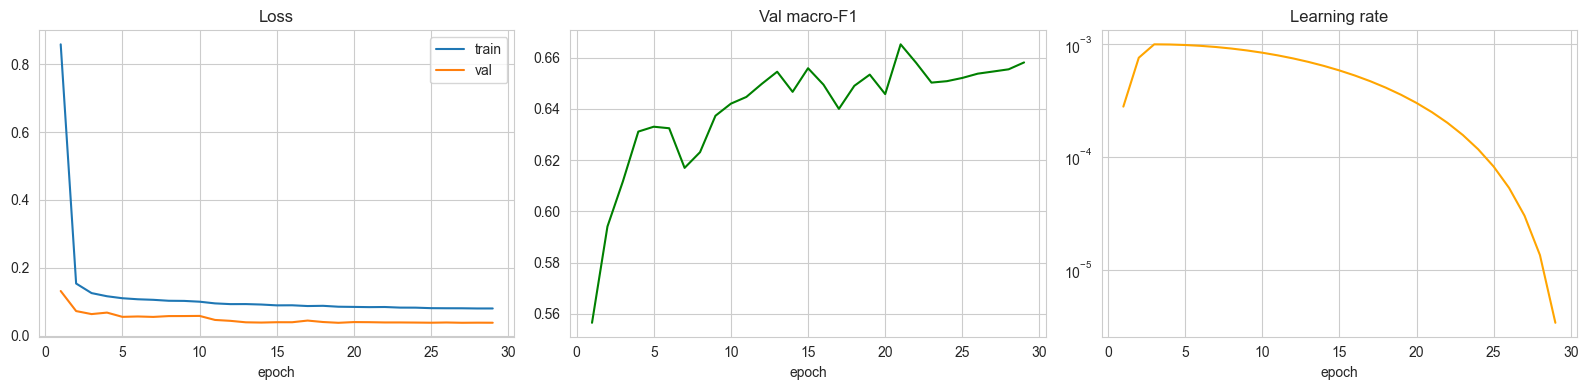

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ep = np.arange(1, len(history['train_loss']) + 1)
axes[0].plot(ep, history['train_loss'], label='train')
axes[0].plot(ep, history['val_loss'],   label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(ep, history['val_f1'], color='green')
axes[1].set_title('Val macro-F1'); axes[1].set_xlabel('epoch')
axes[2].plot(ep, history['lr'], color='orange')
axes[2].set_title('Learning rate'); axes[2].set_xlabel('epoch'); axes[2].set_yscale('log')
plt.tight_layout()
plt.savefig(OUT_DIR / 'training_curves.png', dpi=120)
plt.show()

## 8 - Test evaluation (per-attack precision / recall / F1)

In [11]:
test_loss, test_f1, y_hat, y_ref = evaluate(model, test_loader, criterion)
print(f'Test loss: {test_loss:.4f} | macro-F1: {test_f1:.4f}')

report = classification_report(y_ref, y_hat, target_names=class_names, digits=4, zero_division=0)
print('\n' + report)
with open(OUT_DIR / 'classification_report.txt', 'w') as f:
    f.write(report)

Test loss: 0.0402 | macro-F1: 0.6555

                  precision    recall  f1-score   support

          Benign     0.9948    0.2888    0.4476     60000
          Botnet     0.9942    0.9901    0.9922     21819
  BruteForce-Web     0.0606    0.9186    0.1138        86
  BruteForce-XSS     0.1161    0.7647    0.2016        34
       DDoS-HOIC     0.9987    1.0000    0.9994     30000
  DDoS-LOIC-HTTP     0.9995    0.9933    0.9964     30000
   DDoS-LOIC-UDP     0.7951    1.0000    0.8859       260
   DoS-GoldenEye     0.9966    0.9992    0.9979      6211
        DoS-Hulk     0.9997    0.9996    0.9997     30000
DoS-SlowHTTPTest     0.3913    0.5625    0.4615        16
   DoS-Slowloris     0.9328    1.0000    0.9652      1486
  FTP-BruteForce     0.2500    0.2857    0.2667        14
    Infiltration     0.2988    0.9654    0.4564     18280
   SQL-Injection     0.0248    0.9167    0.0484        12
  SSH-BruteForce     0.9993    0.9998    0.9995     14112

        accuracy                

## 8b - Prior correction (no retraining)

The base model was trained under a ~uniform class prior (thanks to `WeightedRandomSampler`) and is now being evaluated against a natural distribution where Benign dominates. This cell adds `log(P_natural)` to every logit before argmax - a one-line Bayes correction that shifts the decision boundary back toward the real prior. No retraining. If this lifts Benign recall dramatically and the tiny-class precision, the rebalancing diagnosis is confirmed and we can move on to the proper retrain (Option B: disable sampler + lower SMOTE target).

In [ ]:
# --- Option A: Bayes prior correction (no retraining) -----------------------
# Diagnosis: WeightedRandomSampler trained the model under a ~uniform class
# prior, but the test set follows the natural distribution (Benign dominates).
# Fix: add log(P_natural) to every logit so argmax reflects the real prior.
# This cell is self-sufficient if you re-ran cells: imports, data load,
# hyperparameters, dataset, and model definition. It loads the saved checkpoint
# so you do NOT need to re-run the training loop.

# 1. Load the saved trained model
ckpt_path = OUT_DIR / 'bilstm_ids.pt'
assert ckpt_path.exists(), f'Missing checkpoint: {ckpt_path} (run training loop first)'
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
test_f1_prev = float(ckpt.get('test_f1', float('nan')))
print(f'Loaded checkpoint. Previous test macro-F1: {test_f1_prev:.4f}')

# 2. Natural prior from the validation set (don't peek at test)
val_counts = np.bincount(y_val, minlength=num_classes).astype(np.float64)
natural_prior = val_counts / val_counts.sum()
log_prior_adjust = torch.tensor(np.log(natural_prior + 1e-12),
                                 dtype=torch.float32, device=device)

print('\nNatural prior (from val):')
for c, p in enumerate(natural_prior):
    print(f'  {class_names[c]:22s} {p:7.4%}')


@torch.no_grad()
def evaluate_prior_adjusted(model, loader, adj):
    model.eval()
    preds, trues = [], []
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb) + adj           # <-- prior correction
        preds.append(logits.argmax(dim=1).cpu().numpy())
        trues.append(yb.numpy())
    return np.concatenate(preds), np.concatenate(trues)


# 3. Baseline (unadjusted) F1 on current kernel state, for an honest delta
@torch.no_grad()
def evaluate_plain(model, loader):
    model.eval()
    preds, trues = [], []
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        preds.append(model(xb).argmax(dim=1).cpu().numpy())
        trues.append(yb.numpy())
    return np.concatenate(preds), np.concatenate(trues)


y_hat_base, y_ref_base = evaluate_plain(model, test_loader)
base_f1 = f1_score(y_ref_base, y_hat_base, average='macro', zero_division=0)

y_hat_adj, y_ref_adj = evaluate_prior_adjusted(model, test_loader, log_prior_adjust)
adj_f1 = f1_score(y_ref_adj, y_hat_adj, average='macro', zero_division=0)

print(f'\nMacro-F1 BEFORE prior adjustment: {base_f1:.4f}')
print(f'Macro-F1 AFTER  prior adjustment: {adj_f1:.4f}  (delta {adj_f1 - base_f1:+.4f})')

report_adj = classification_report(y_ref_adj, y_hat_adj, target_names=class_names,
                                    digits=4, zero_division=0)
print('\n' + report_adj)
with open(OUT_DIR / 'classification_report_prior_adjusted.txt', 'w') as f:
    f.write(report_adj)

# 4. Per-class F1 bar (adjusted)
adj_per_class_f1 = f1_score(y_ref_adj, y_hat_adj, average=None,
                             labels=np.arange(num_classes), zero_division=0)
order = np.argsort(adj_per_class_f1)
fig, ax = plt.subplots(figsize=(11, 5))
colors = ['crimson' if f < 0.5 else 'orange' if f < 0.8 else 'seagreen'
          for f in adj_per_class_f1[order]]
ax.barh([class_names[i] for i in order], adj_per_class_f1[order], color=colors)
ax.set_xlim(0, 1); ax.set_xlabel('F1')
ax.set_title(f'Per-attack F1 after prior adjustment (macro={adj_f1:.3f})')
for i, f in enumerate(adj_per_class_f1[order]):
    ax.text(f + 0.01, i, f'{f:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / 'per_attack_f1_prior_adjusted.png', dpi=120)
plt.show()

# 5. Confusion matrix (adjusted)
cm_adj = confusion_matrix(y_ref_adj, y_hat_adj, labels=np.arange(num_classes))
cm_adj_norm = cm_adj / cm_adj.sum(axis=1, keepdims=True).clip(min=1)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm_adj, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion matrix (counts, prior-adjusted)')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
sns.heatmap(cm_adj_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion matrix (row-normalized recall, prior-adjusted)')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_matrix_prior_adjusted.png', dpi=120)
plt.show()


## 9 - Confusion matrix

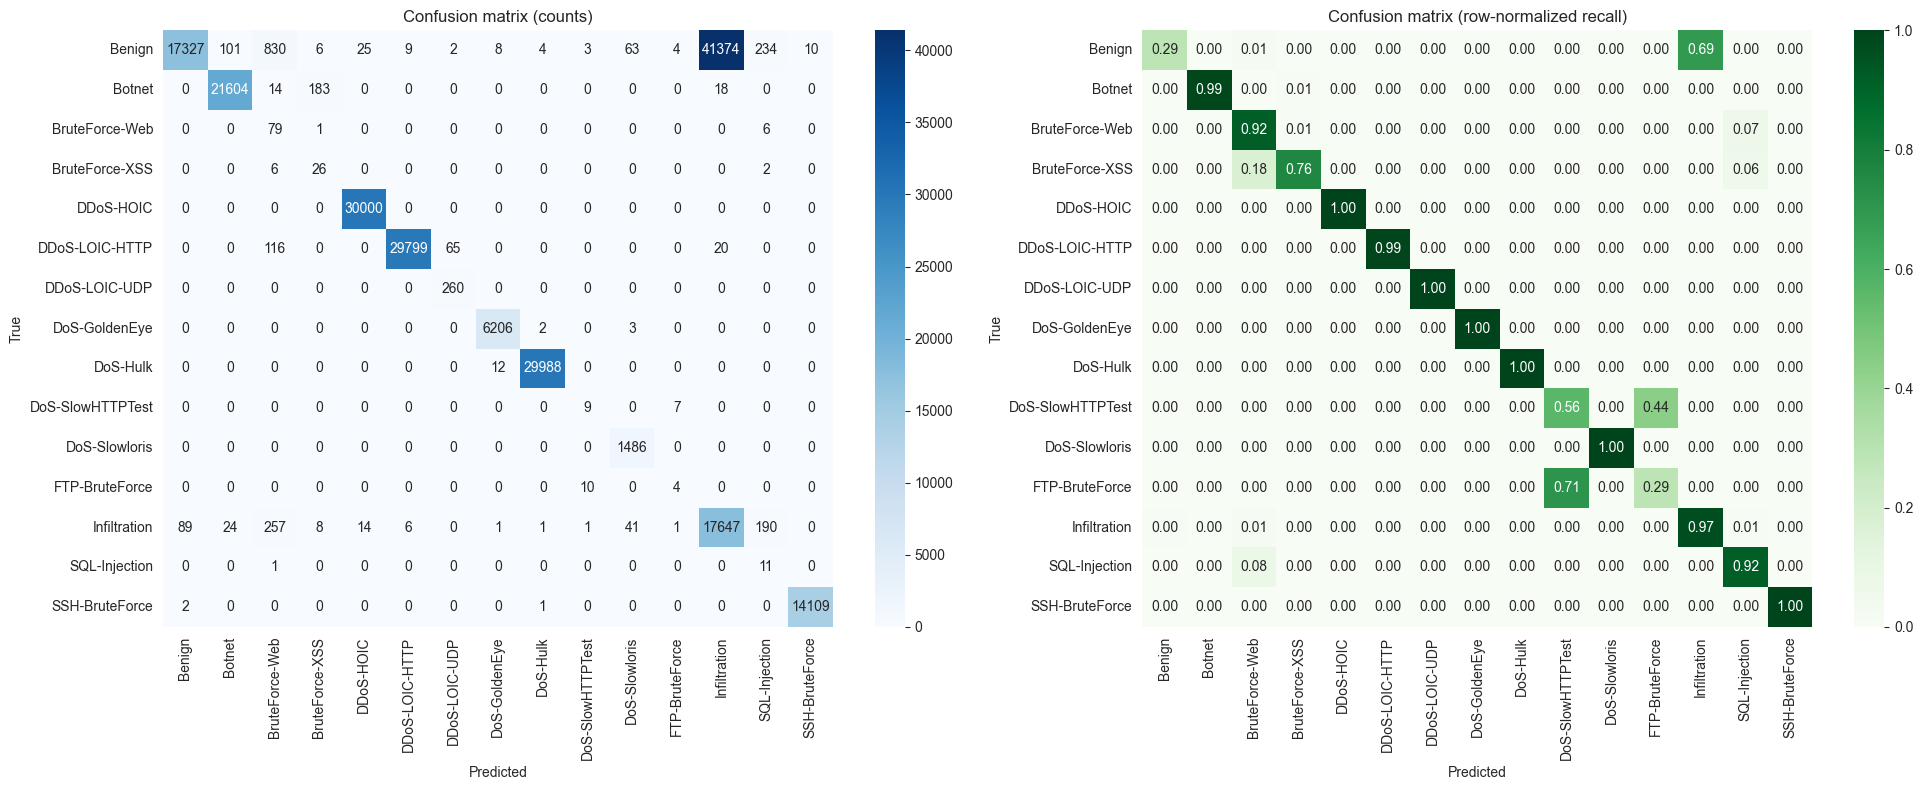

In [12]:
cm = confusion_matrix(y_ref, y_hat, labels=np.arange(num_classes))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion matrix (counts)')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion matrix (row-normalized recall)')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_matrix.png', dpi=120)
plt.show()

## 10 - Per-attack F1 bar chart

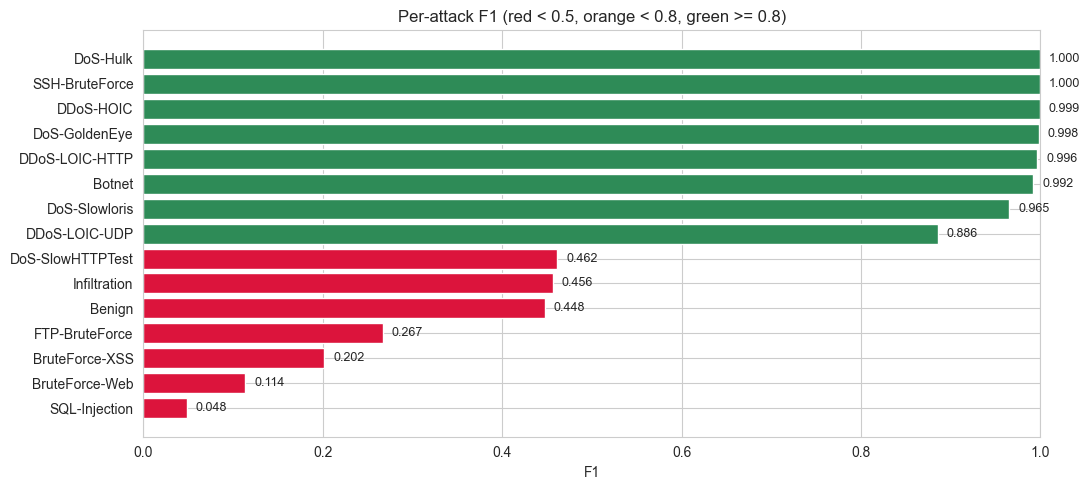

In [13]:
per_class_f1 = f1_score(y_ref, y_hat, average=None, labels=np.arange(num_classes), zero_division=0)
order = np.argsort(per_class_f1)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ['crimson' if f < 0.5 else 'orange' if f < 0.8 else 'seagreen' for f in per_class_f1[order]]
ax.barh([class_names[i] for i in order], per_class_f1[order], color=colors)
ax.set_xlim(0, 1)
ax.set_xlabel('F1')
ax.set_title('Per-attack F1 (red < 0.5, orange < 0.8, green >= 0.8)')
for i, f in enumerate(per_class_f1[order]):
    ax.text(f + 0.01, i, f'{f:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / 'per_attack_f1.png', dpi=120)
plt.show()

## 11 - Per-class ROC curves (one-vs-rest)

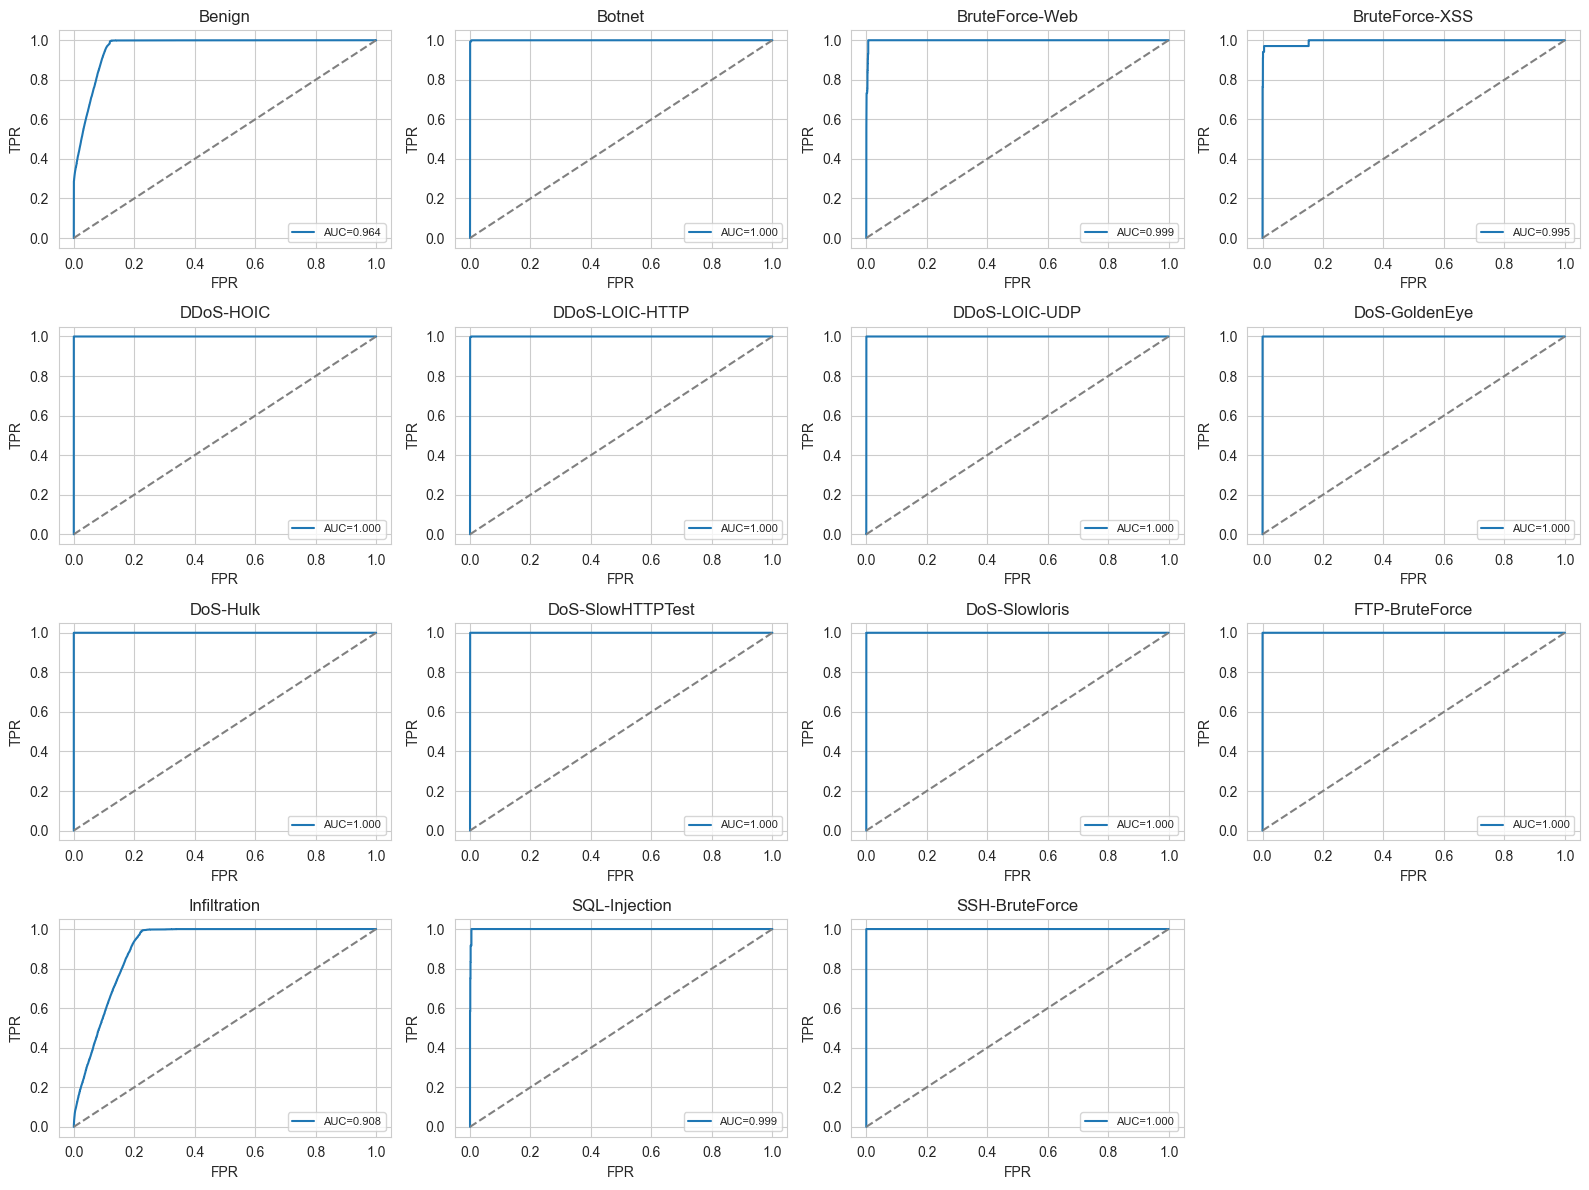

In [14]:
@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    probs = []
    for xb, _ in loader:
        xb = xb.to(device, non_blocking=True)
        probs.append(F.softmax(model(xb), dim=-1).cpu().numpy())
    return np.concatenate(probs)


y_proba = predict_proba(model, test_loader)
y_bin   = label_binarize(y_ref, classes=np.arange(num_classes))

n_cols = 4
n_rows = (num_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.flatten()
for k in range(num_classes):
    if y_bin[:, k].sum() == 0:
        axes[k].set_title(f'{class_names[k]} (no positives)')
        continue
    fpr, tpr, _ = roc_curve(y_bin[:, k], y_proba[:, k])
    auc_k = auc(fpr, tpr)
    axes[k].plot(fpr, tpr, label=f'AUC={auc_k:.3f}')
    axes[k].plot([0, 1], [0, 1], ls='--', color='grey')
    axes[k].set_title(class_names[k])
    axes[k].set_xlabel('FPR'); axes[k].set_ylabel('TPR'); axes[k].legend(loc='lower right', fontsize=8)
for k in range(num_classes, len(axes)):
    fig.delaxes(axes[k])
plt.tight_layout()
plt.savefig(OUT_DIR / 'roc_per_class.png', dpi=120)
plt.show()

## 12 - Per-class Precision-Recall curves

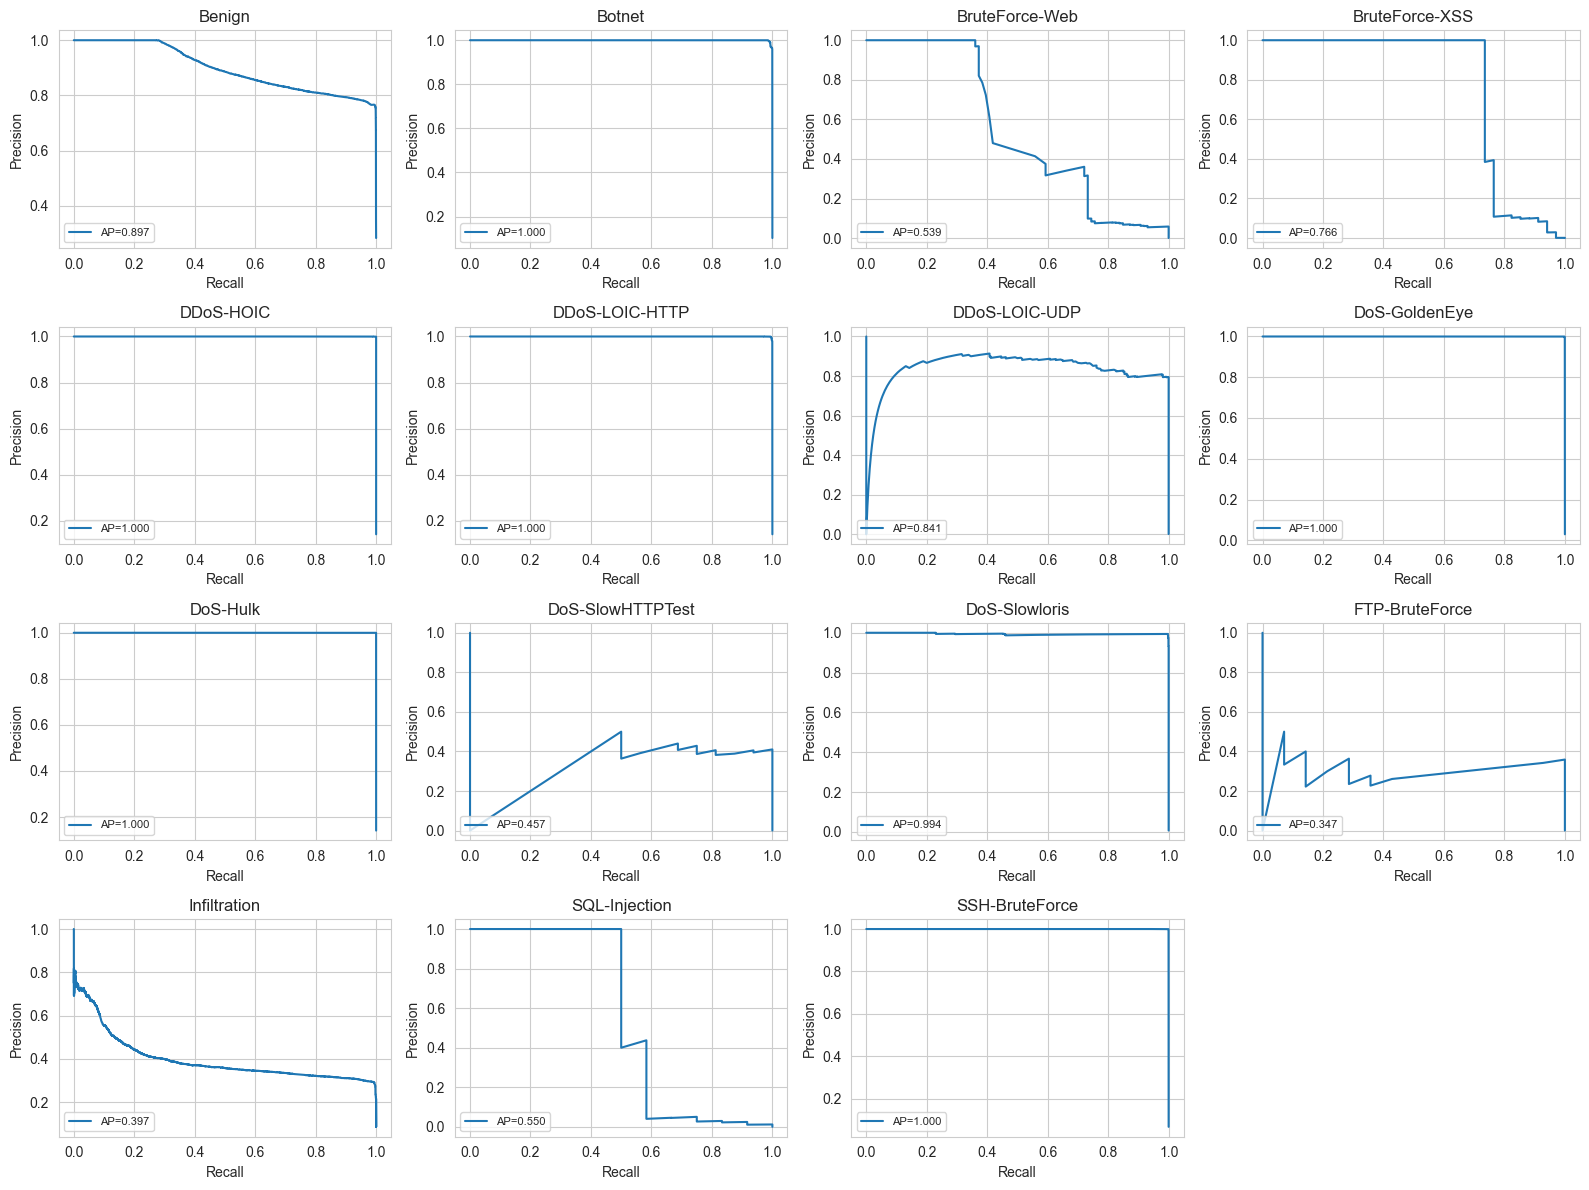

In [15]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.flatten()
for k in range(num_classes):
    if y_bin[:, k].sum() == 0:
        axes[k].set_title(f'{class_names[k]} (no positives)')
        continue
    p, r, _ = precision_recall_curve(y_bin[:, k], y_proba[:, k])
    ap = average_precision_score(y_bin[:, k], y_proba[:, k])
    axes[k].plot(r, p, label=f'AP={ap:.3f}')
    axes[k].set_title(class_names[k])
    axes[k].set_xlabel('Recall'); axes[k].set_ylabel('Precision'); axes[k].legend(loc='lower left', fontsize=8)
for k in range(num_classes, len(axes)):
    fig.delaxes(axes[k])
plt.tight_layout()
plt.savefig(OUT_DIR / 'pr_per_class.png', dpi=120)
plt.show()

## 13 - Save model & artifacts

In [16]:
torch.save({
    'model_state_dict': model.state_dict(),
    'config': {
        'input_dim': CHUNK, 'hidden': HIDDEN, 'num_layers': LSTM_LAYERS,
        'num_classes': num_classes, 'dropout': DROPOUT,
        'pad_to': PAD_TO, 'chunk': CHUNK, 'num_features': num_features,
    },
    'class_names': class_names,
    'best_val_f1': best_f1,
    'test_f1': test_f1,
}, OUT_DIR / 'bilstm_ids.pt')

with open(OUT_DIR / 'history.json', 'w') as f:
    json.dump(history, f, indent=2)

print(f'Saved to {OUT_DIR}')
for p in sorted(OUT_DIR.iterdir()):
    print(f'  - {p.name}')

Saved to outputs
  - bilstm_ids.pt
  - classification_report.txt
  - confusion_matrix.png
  - history.json
  - per_attack_f1.png
  - pr_per_class.png
  - roc_per_class.png
  - training_curves.png


## 14 - Inference helper

In [17]:
def predict_flow(model, scaler, label_encoder, raw_features, pad_to, chunk, device):
    """raw_features: 1-D numpy array of the same feature order the preprocessor produced."""
    x = np.asarray(raw_features, dtype=np.float32).reshape(1, -1)
    x = scaler.transform(x).astype(np.float32)
    if x.shape[1] < pad_to:
        x = np.pad(x, ((0, 0), (0, pad_to - x.shape[1])))
    x = x.reshape(1, pad_to // chunk, chunk)
    with torch.no_grad():
        logits = model(torch.from_numpy(x).to(device))
        probs  = F.softmax(logits, dim=-1).cpu().numpy()[0]
    idx = int(probs.argmax())
    return label_encoder.inverse_transform([idx])[0], float(probs[idx]), probs


# Smoke test with a single test flow
sample_raw = scaler.inverse_transform(X_test[:1])[0]
label, conf, _ = predict_flow(model, scaler, label_encoder, sample_raw, PAD_TO, CHUNK, device)
print(f'Sample predicted: {label} (conf={conf:.3f}) | true: {class_names[y_test[0]]}')

Sample predicted: Infiltration (conf=0.651) | true: Infiltration
